In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

In [ ]:
url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
df = pd.read_csv(url)

df['HighGlucose'] = (df['Glucose'] > 120).astype(int)
df['HighBMI'] = (df['BMI'] > 30).astype(int)

display(df[['Glucose', 'HighGlucose', 'BMI', 'HighBMI', 'Outcome']].head())

,Glucose,HighGlucose,BMI,HighBMI,Outcome
0,148,1,33.6,1,1
1,85,0,26.6,0,0
2,183,1,23.3,0,1
3,89,0,28.1,0,0
4,137,1,43.1,1,1


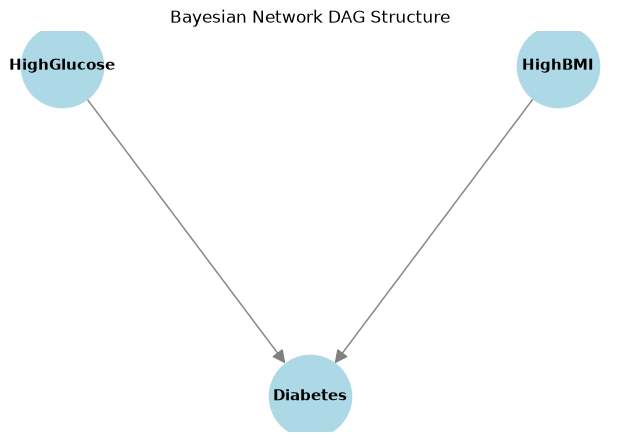

In [ ]:
G = nx.DiGraph()
G.add_edge('HighGlucose', 'Diabetes')
G.add_edge('HighBMI', 'Diabetes')

pos = {'HighGlucose': (0, 1), 'HighBMI': (2, 1), 'Diabetes': (1, 0)}

plt.figure(figsize=(6, 4))
nx.draw(G, pos, with_labels=True, node_color='lightblue', edge_color='gray',
        node_size=3500, font_size=11, font_weight='bold', arrows=True,
        arrowsize=20, arrowstyle='-|>', connectionstyle='arc3,rad=0.0')
plt.title('Bayesian Network DAG Structure')
plt.axis('off')
plt.show()

In [ ]:
def estimate_likelihood(high_glucose, high_bmi):
    subset = df[(df['HighGlucose'] == high_glucose) & (df['HighBMI'] == high_bmi)]

    prob_diabetes = len(subset[subset['Outcome'] == 1]) / len(subset) if len(subset) > 0 else 0
    prob_no_diabetes = 1 - prob_diabetes

    return {'Diabetes': prob_diabetes, 'NoDiabetes': prob_no_diabetes}

probabilities = estimate_likelihood(high_glucose=1, high_bmi=1)
print("Conditional Probabilities given HighGlucose=1 and HighBMI=1:")
print(probabilities)

Conditional Probabilities given HighGlucose=1 and HighBMI=1:
{'Diabetes': 0.657258064516129, 'NoDiabetes': 0.342741935483871}


In [ ]:
print(f"Estimated Likelihood of Diabetes: {probabilities['Diabetes'] * 100:.2f}%")

Estimated Likelihood of Diabetes: 65.73%


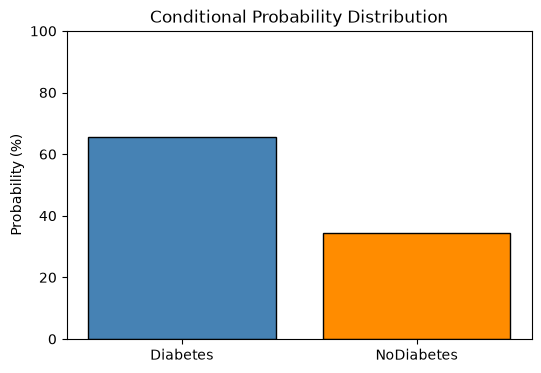

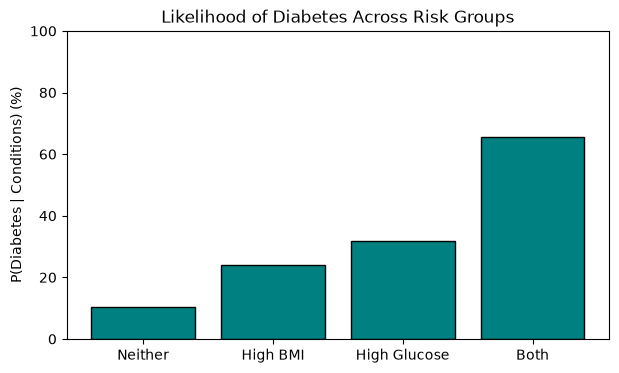

In [ ]:
categories = list(probabilities.keys())
values = [probabilities[k] * 100 for k in categories]

plt.figure(figsize=(6, 4))
plt.bar(categories, values, color=['steelblue', 'darkorange'], edgecolor='black')
plt.title('Conditional Probability Distribution')
plt.ylabel('Probability (%)')
plt.ylim(0, 100)
plt.show()

combinations = [(0, 0), (0, 1), (1, 0), (1, 1)]
labels = ['Neither', 'High BMI', 'High Glucose', 'Both']
probs = [estimate_likelihood(g, b)['Diabetes'] * 100 for g, b in combinations]

plt.figure(figsize=(7, 4))
plt.bar(labels, probs, color='teal', edgecolor='black')
plt.title('Likelihood of Diabetes Across Risk Groups')
plt.ylabel('P(Diabetes | Conditions) (%)')
plt.ylim(0, 100)
plt.show()